In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# استيراد المكتبات (نفتح الأدوات اللي رح نستخدمها، لازم بكل ملف)
import pandas as pd              # للجداول: قراءة، تنظيف، استكشاف
import numpy as np               # للحسابات والأرقام
import matplotlib.pyplot as plt  # للرسومات الأساسية
import seaborn as sns            # لرسومات أحلى، مبنية فوق matplotlib
# ملاحظة: ما استوردنا sklearn لأن Windows منعها على جهازي
print("malak ml1")               # للتأكد إن كل شي تحمّل

In [ ]:

# الخطوة 2: تحميل البيانات
DATA_PATH = "german_credit_data.csv"   # اسم الملف بمتغير، أسهل نغيره بعدين
dataset = pd.read_csv(DATA_PATH)       # نقرأ الملف ونحطه بجدول اسمه dataset
print(dataset.shape)                   # حجم الجدول (صفوف، أعمدة)، المتوقع (1000, 10)
dataset.head()                         # أول 5 صفوف، نظرة سريعة على البيانات
# NaN = خانة فاضية (قيمة ناقصة)

(1000, 10)


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
dataset.dtypes
# بعطيني ايش نوع كل عمود ,لتاكد ان بايثون فهم كل عمود بشكل صحيح #

Age                int64
Sex                  str
Job                int64
Housing              str
SavingAccounts       str
CheckingAccount      str
CreditAmount       int64
Duration           int64
Purpose              str
Risk                 str
dtype: object

In [ ]:
dataset.describe()
# تظهر الاعمدة الرقمية ,    وتعرض عدد القيم والمتوسط والانحراف المعياري ,تعلى قيمة واصغرها والنسب الي تقع عندها القيم #


,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [ ]:
dataset.describe(exclude="number")
#يستبعد الأعمدة الرقمية ويلخص الأعمدة غير الرقمية#   
#COUNT عدد القيم الموجودة 
#unique عدد الفئات المختلفة 
#top الفئة الاكثر تكرار
#freq عدد مرات ظهور الفئة الاكثر 


,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [ ]:
dataset.isna().sum()
#بفحص القيم الي مش موجودة وبجمعها لكل عامود ويعرض العدد في المخرجات #



Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64

In [ ]:
print(dataset["Risk"].value_counts())
#يختار عامود الRISK ,ويحسب عدد مرات ظهور كل فئة #
print(dataset["Risk"].value_counts(normalize=True) * 100)
#يحول النسب العشرية الى نسب مئوية #


Risk
good    700
bad     300
Name: count, dtype: int64
Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

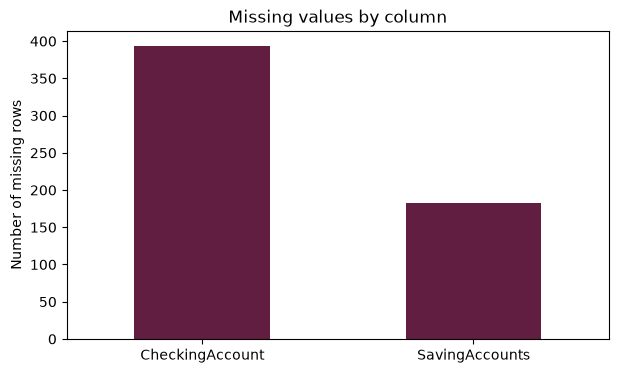

In [ ]:
missing = dataset.isna().sum()
#نحسب القيم المفقودة لكل عمود، كما فعلنا في الكود السابق#
missing = missing[missing > 0].sort_values(ascending=False)
#نحتفظ بالأعمدة التي لديها قيمة مفقودة واحدة على الأقل، ونستبعد الأعمدة التي عدد القيم المفقودة فيها صفر
#نرتب النتائج من الأكبر إلى الأصغر؛ أي العمود الذي لديه أكبر عدد من القيم المفقودة يظهر أولًا
plt.figure(figsize=(7, 4))
#نحدد حجم الرسم
missing.plot(kind="bar", color="#611E41")
#kind="bar" يرسم مخطط أعمدة
#color يحدد لون الأعمدة
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
#نضع عنوانًا للمحور الرأسي، وهو عدد الصفوف ذات القيم المفقودة.
plt.xticks(rotation=0)
#نجعل أسماء الأعمدة أفقية بدل تدويرها
plt.show
#يعرض الرسم
#ول إشي بنطلع الأعمدة اللي فيها خانات فاضية، وبعدين بنرسمها. الرسم بيسهّل علينا نعرف أي عمود فيه نقص أكبر

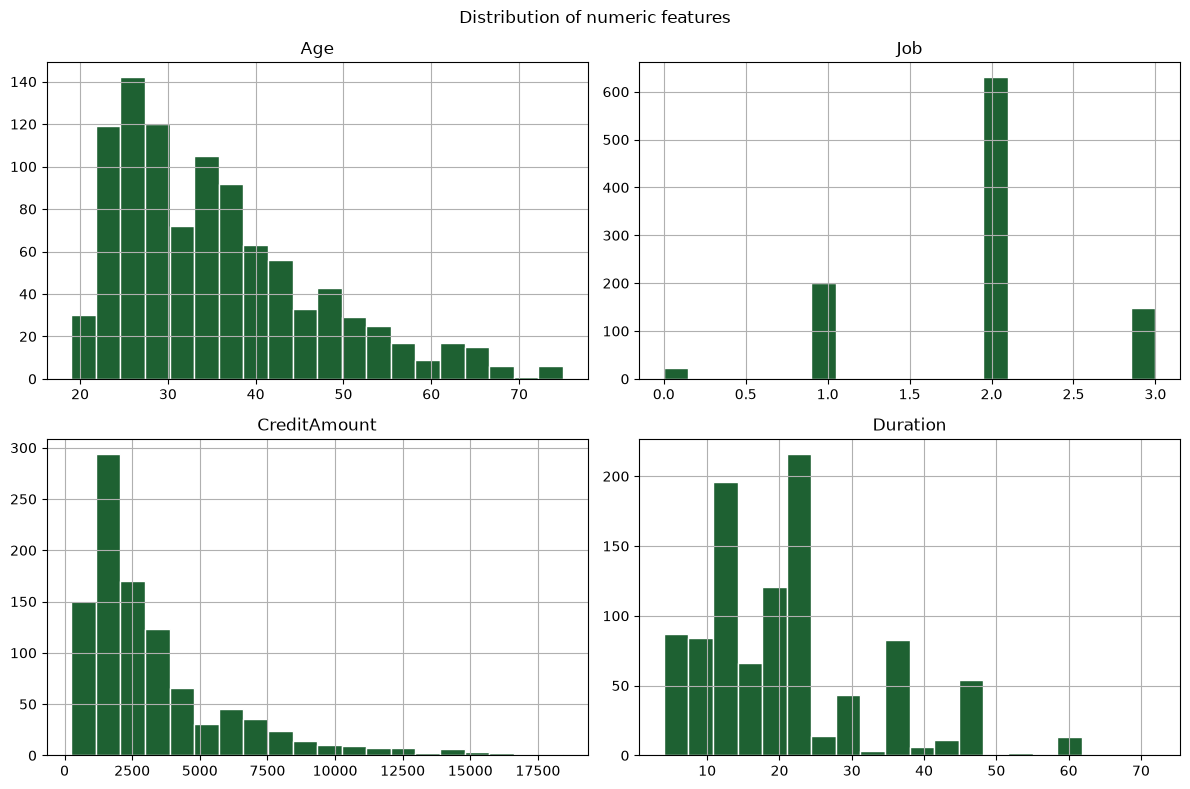

In [ ]:
# قائمة الأعمدة الرقمية (بنستخدمها كثير بالخلايا الجاية)
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

# Histogram: كيف القيم موزعة لكل عمود
# ملاحظة: CreditAmount فيه ذيل طويل لليمين (التواء)
# Duration فيه قمم عند 12 و 24 و 36 لأن القروض بمدد ثابتة
dataset[numeric_cols].hist(
    figsize=(12, 8),        # حجم الرسمة (طولناها شوي)
    bins=20,                # عدد الأعمدة بكل رسمة
    color="#1E6132",        # لون الأعمدة (كحلي)
    edgecolor="white"       # خط أبيض حوالين كل عمود، عشان ينفصلوا عن بعض
)
plt.suptitle("Distribution of numeric features")   # عنوان كبير لكل الرسومات
plt.tight_layout()                                  # ترتيب ما يتداخلوا
plt.show()

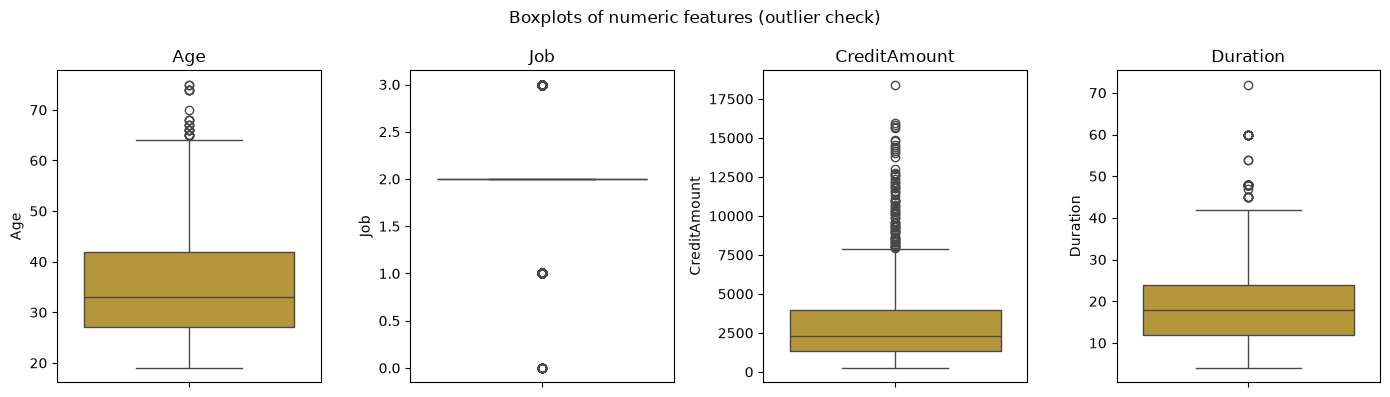

In [ ]:
# Boxplot: لكشف القيم الشاذة (outliers)
# الصندوق = النص اللي بالنص (25% لـ 75%)، الخط جوّا = الوسيط، النقاط = قيم شاذة
fig, axes = plt.subplots(1, 4, figsize=(14, 4))    # صف واحد فيه 4 أماكن للرسم

for ax, col in zip(axes, numeric_cols):            # لكل عمود مكان
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)                              # اسم العمود فوق الرسمة

plt.suptitle("Boxplots of numeric features (outlier check)")
plt.tight_layout()                                 # ترتيب ما يتداخلوا
plt.show()
# ملاحظة: القيمة الشاذة مش دايماً غلط (قرض 18000 منطقي)

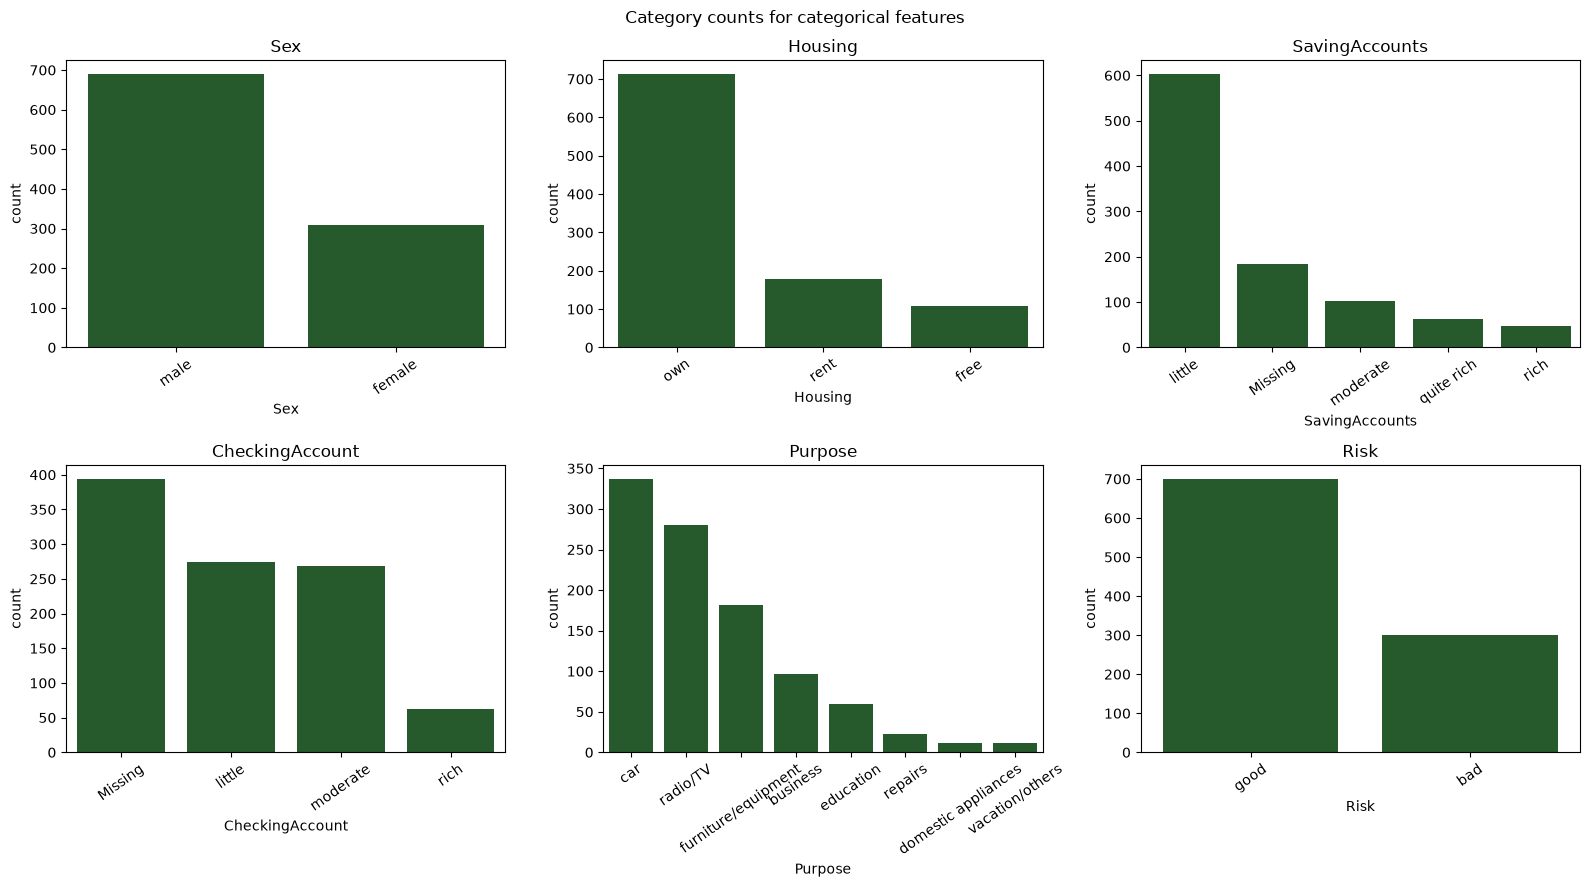

In [ ]:
# قائمة الأعمدة النصية
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# Count plot: كم واحد بكل فئة
fig, axes = plt.subplots(2, 3, figsize=(16, 9))    # شبكة صفين × 3
axes = axes.flatten()                              # نحوّلها لسطر واحد من 6

for ax, col in zip(axes, categorical_cols):
    col_data = dataset[col].fillna("Missing")      # الفاضي يظهر كعمود "Missing" (للرسم بس)
    order = col_data.value_counts().index          # ترتيب من الأكثر للأقل
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E6125")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)          # نميّل الكلمات تحت

plt.suptitle("Category counts for categorical features")
plt.tight_layout()
plt.show()
# ملاحظة: بـ CheckingAccount، "Missing" هو الأكبر! فما لازم نحذفه


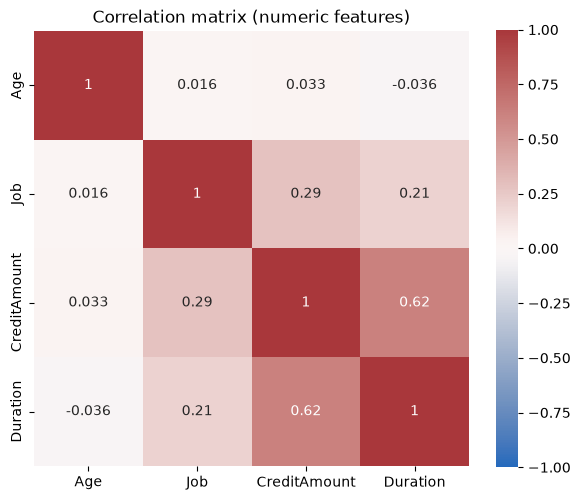

In [ ]:
# Correlation: قديش كل عمودين مرتبطين (من -1 لـ +1)
# +1 = بيزيدوا مع بعض، -1 = واحد بيزيد والثاني بينقص، 0 = ما في علاقة
correlation = dataset[numeric_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
# annot=True = اكتب الرقم بكل مربع، cmap = الألوان (أحمر موجب، أزرق سالب)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

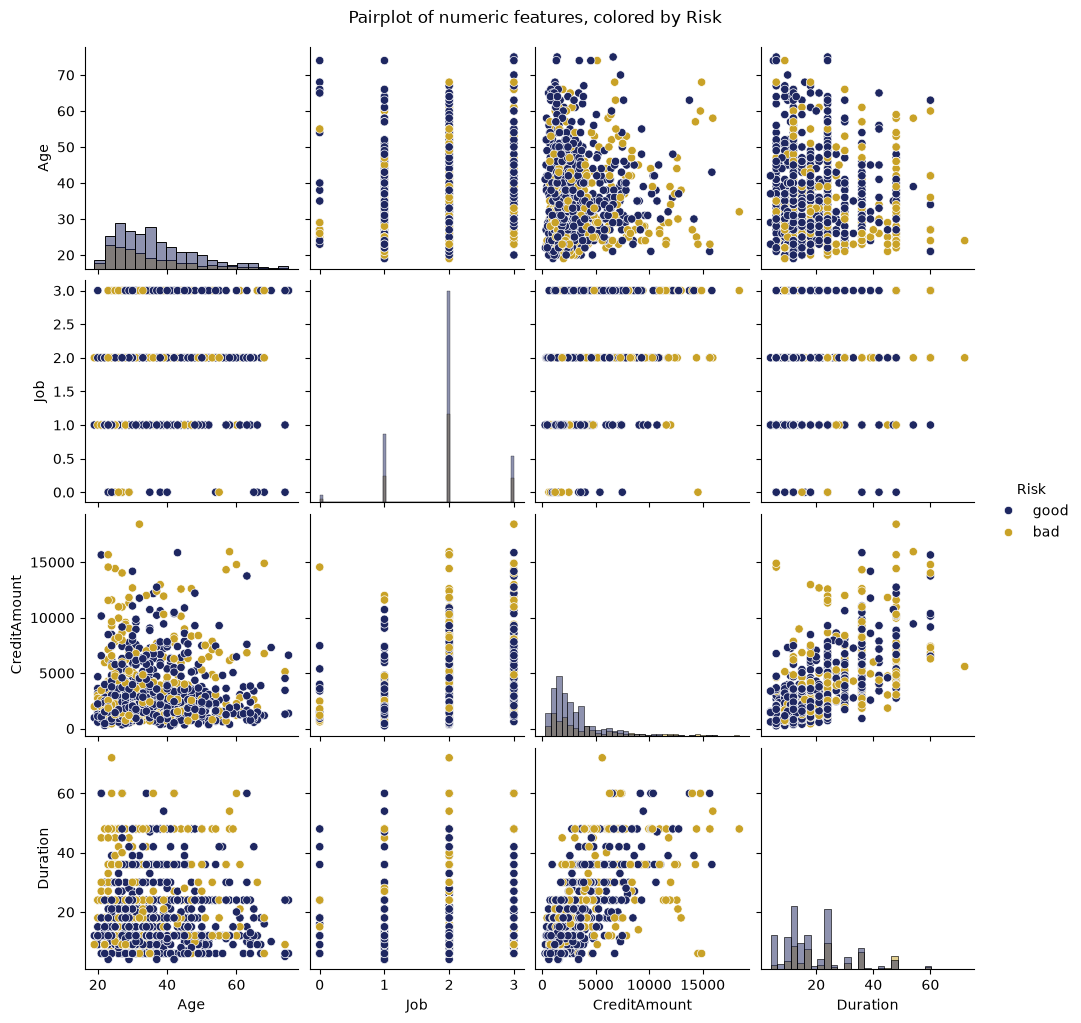

In [ ]:
# Pairplot: كل عمود رقمي مقابل كل عمود، ملونين حسب Risk
# السؤال: هل good و bad منفصلين؟ لو مخلوطين = بنحتاج موديل ML
sns.pairplot(
    dataset,
    vars=numeric_cols,                                   # الأعمدة الرقمية بس
    hue="Risk",                                          # لوّن حسب الجواب
    palette={"good": "#1E2761", "bad": "#C9A227"},       # كحلي = good، ذهبي = bad
    diag_kind="hist"                                     # على القطر histogram
)
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

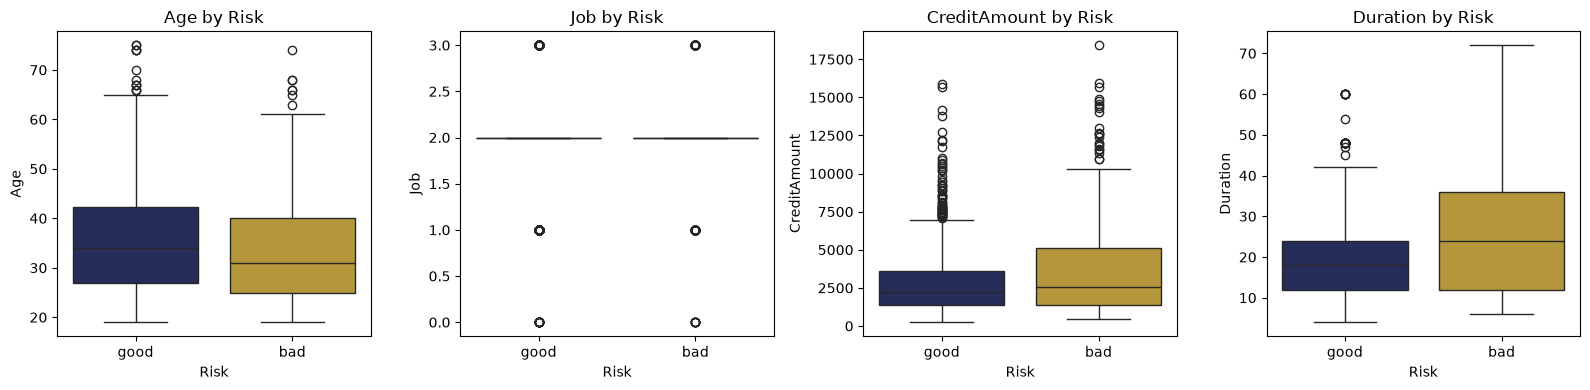

In [ ]:
# Boxplot مقسوم حسب Risk: هل توزيع كل عمود مختلف بين good و bad؟
# لو في فرق واضح بين الصندوقين = العمود ممكن يكون مفيد للموديل
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))   # صف واحد، رسمة لكل عمود رقمي

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=dataset,
        x="Risk",                                        # تحت: good و bad
        y=col,                                           # فوق: قيم العمود
        hue="Risk",                                      # لوّن كل صندوق حسب Risk
        palette={"good": "#1E2761", "bad": "#C9A227"},   # كحلي = good، ذهبي = bad
        legend=False,                                    # بلا مفتاح ألوان (واضح من تحت)
        ax=ax
    )
    ax.set_title(f"{col} by Risk")                       # العنوان، مثلاً "Age by Risk"

plt.tight_layout()
plt.show()

# التفسير: الـ bad عندهم CreditAmount و Duration أعلى شوي
# يعني القروض الأكبر والأطول أخطر، وهاد منطقي مالياً

In [ ]:
# الخطوة 4: تجهيز البيانات
# 4.1 التنظيف: نعبي الفراغات بـ "none" بدل ما نحذفها
# ليش؟ الفراغ معناه "ما عنده حساب" (معلومة)، والحذف كان رح يخسرنا 40% من البيانات
df_clean = dataset.copy()   # نسخة عشان الأصلي يضل سليم

df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

print("Remaining missing values:")
print(df_clean.isna().sum())   # نتأكد: المفروض كله 0

Remaining missing values:
Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


In [ ]:
# 4.2 التحويل (Encoding): نحوّل الكلمات لأرقام لأن الموديل بيفهم أرقام بس
# الترتيب أبجدي، مثلاً female=0 و male=1، و bad=0 و good=1
# مشكلة: "none" صار رقمه 2 بين moderate و quite rich (ترتيب وهمي)
# الحل الأفضل للفئات بدون ترتيب: One-hot encoding
df_encoded = df_clean.copy()

for col in categorical_cols:
    categories = df_clean[col].astype("category")      # نحوّل العمود لنوع "فئات"
    df_encoded[col] = categories.cat.codes             # نعطي كل فئة رقم
    print(col, "->", list(categories.cat.categories))  # نطبع الترتيب عشان نعرف كل رقم شو معناه

Sex -> ['female', 'male']
Housing -> ['free', 'own', 'rent']
SavingAccounts -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount -> ['little', 'moderate', 'none', 'rich']
Purpose -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk -> ['bad', 'good']


In [ ]:
# التوحيد (Scaling): نخلي كل الأعمدة الرقمية على نفس المقياس
# المتوسط بيصير 0 والانحراف المعياري 1
# ليش؟ عشان القرض (بالآلاف) ما يطغى على العمر (بالعشرات)
# المعادلة: (القيمة - المتوسط) ÷ الانحراف المعياري
df_scaled = df_encoded.copy()

for col in numeric_cols:
    mean = df_encoded[col].mean()        # المتوسط
    std = df_encoded[col].std(ddof=0)    # الانحراف المعياري
    df_scaled[col] = (df_encoded[col] - mean) / std   # تطبيق المعادلة

# نقارن أول 3 صفوف قبل وبعد
print("Before scaling:")
print(df_encoded[numeric_cols].head(3))
print("\nAfter scaling:")
print(df_scaled[numeric_cols].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling:
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


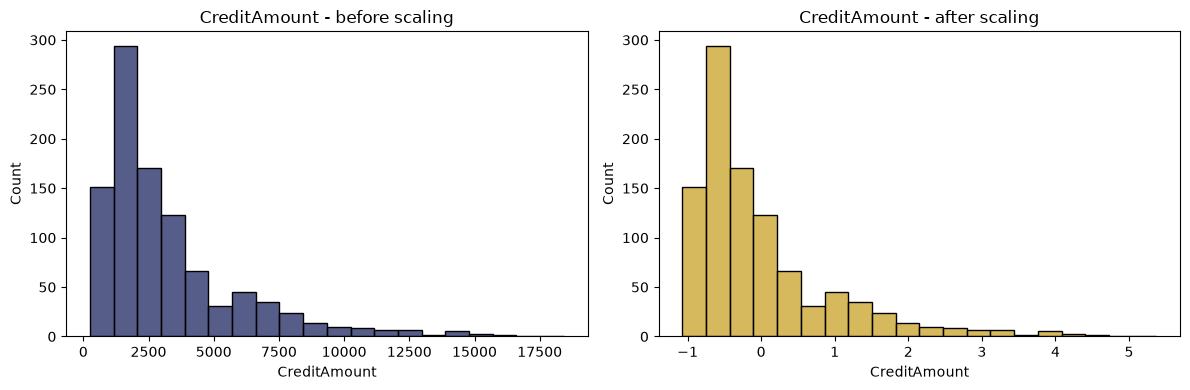

In [ ]:
# فحص بصري: الـ Scaling بيغيّر أرقام المحور، بس ما بيغيّر شكل التوزيع
# يعني الالتواء (skew) بيضل موجود بعد التوحيد
fig, axes = plt.subplots(1, 2, figsize=(12, 4))    # رسمتين جنب بعض

# قبل التوحيد (من df_encoded)
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount - before scaling")

# بعد التوحيد (من df_scaled)
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#C9A227")
axes[1].set_title("CreditAmount - after scaling")

plt.tight_layout()
plt.show()
# النتيجة: نفس الشكل بالضبط، بس المحور صار من -1 لـ 5 بدل من 0 لـ 18000

In [ ]:
# اختيار الأعمدة: نعطي كل عمود علامة حسب قديش بيفرّق بين good و bad
# X = المعلومات، y = الجواب (Risk)
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

n = len(y)
scores = {}

for col in X.columns:
    overall_mean = X[col].mean()                  # متوسط العمود لكل الناس
    groups = X[col].groupby(y)                    # نقسم الناس: good و bad
    # الفرق بين المجموعتين (كل ما كبر = العمود بيفرّق أكثر)
    between = (groups.count() * (groups.mean() - overall_mean) ** 2).sum()
    # التفرّق جوّا كل مجموعة (الضجة)
    within = ((X[col] - groups.transform("mean")) ** 2).sum()
    # العلامة = الفرق بين المجموعات ÷ الضجة
    scores[col] = (between / 1) / (within / (n - 2))

# نرتب الأعمدة من الأهم للأقل
feature_scores = pd.Series(scores).sort_values(ascending=False)
feature_scores

CheckingAccount    111.721482
Duration            48.333790
SavingAccounts      33.948465
CreditAmount        24.482366
Age                  8.356995
Sex                  5.720350
Purpose              3.745234
Job                  1.070584
Housing              0.372463
dtype: float64

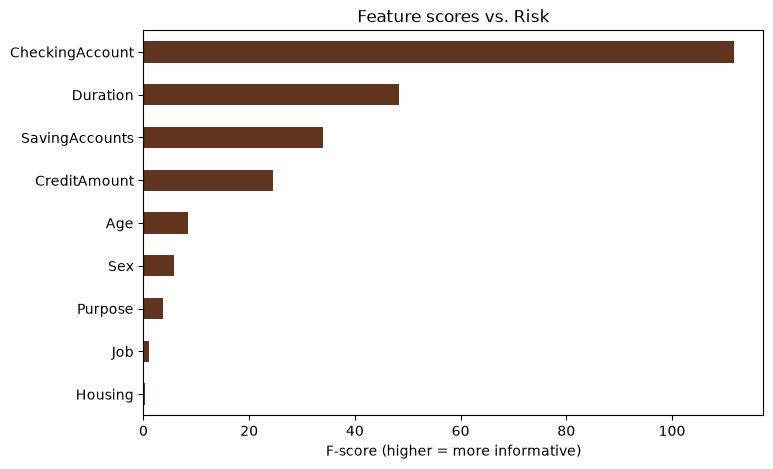

In [ ]:
# رسمة أعمدة لعلامة كل عمود، الأطول = الأهم
plt.figure(figsize=(8, 5))
feature_scores.sort_values().plot(kind="barh", color="#61341E")
plt.title("Feature scores vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.show()